In [158]:
import sys
sys.path.append("../")
from collections import defaultdict

import pyarrow.feather as feather
import numpy as np
import itertools
from pathlib import Path
from utils import *

from tqdm.auto import tqdm

import seaborn as sns
sns.set_context("notebook", font_scale=1.2)
colors = sns.color_palette("muted")

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size" : 15,
                     "figure.dpi" : 100, 
                     "grid.alpha" : 0.3, 
                     "axes.grid": False, 
                     "axes.axisbelow" : True,
                     "figure.figsize":(8,6),
                     "mathtext.fontset":"cm",
                     "xtick.labelsize": 14,
                     "ytick.labelsize": 14,
                     "axes.labelsize": 16, 
                     "legend.fontsize": 13.5})
plt.rc("text", usetex=False)
plt.rc("font", family="serif")

In [159]:
DATA_DIR = Path("../data/sweep_2026_03_05_1227/")
sim_df = feather.read_feather(DATA_DIR / "simulations.arrow")
node_df = feather.read_feather(DATA_DIR / "nodes.arrow")
print("Simulations:", sim_df.shape)
print("Nodes:", node_df.shape)

Simulations: (50000, 13)
Nodes: (15000000, 13)


### Compute Normalized Agent Reputations

In [161]:
def compute_normalized_rep(row):
    rep = row["reputation"]
    best = row["best_reputation"]
    worst = row["worst_reputation"]
    
    if rep < 0 and worst != 0:
        return - (rep / worst)
    elif rep > 0 and best != 0:
        return rep / best
    else:
        return 0.0

node_df["normalized_rep"] = node_df.apply(compute_normalized_rep, axis=1)

# proportion of all agents with 0 final reputation
print(round(len(node_df[node_df["reputation"]==0]) / len(node_df), 2))

0.27


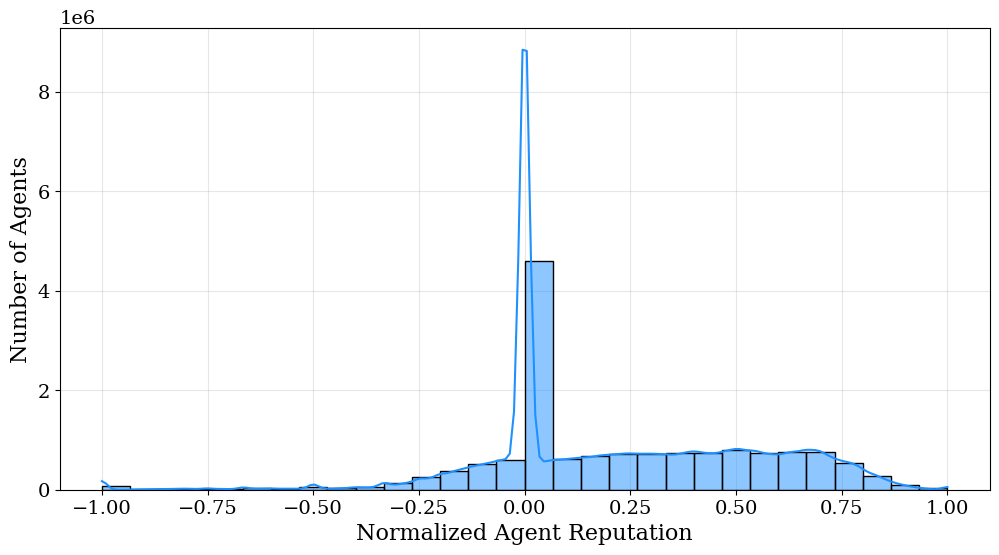

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(node_df['normalized_rep'], bins=30, kde=True, color='dodgerblue')
plt.xlabel("Normalized Agent Reputation")
plt.ylabel("Number of Agents")
plt.grid()
plt.show()

### Compute Sen Welfare For Each Simulation

In [ ]:
# compute sen welfare per simulation
sen_values = (
    node_df
    .groupby("global_sim_id")["normalized_rep"]
    .apply(lambda x: sen_welfare(x.values))
    .reset_index()
    .rename(columns={"normalized_rep": "sen_welfare"})
)

sim_df = sim_df.merge(sen_values, on="global_sim_id")

### Sen Welfare Distribution Across All Simulations

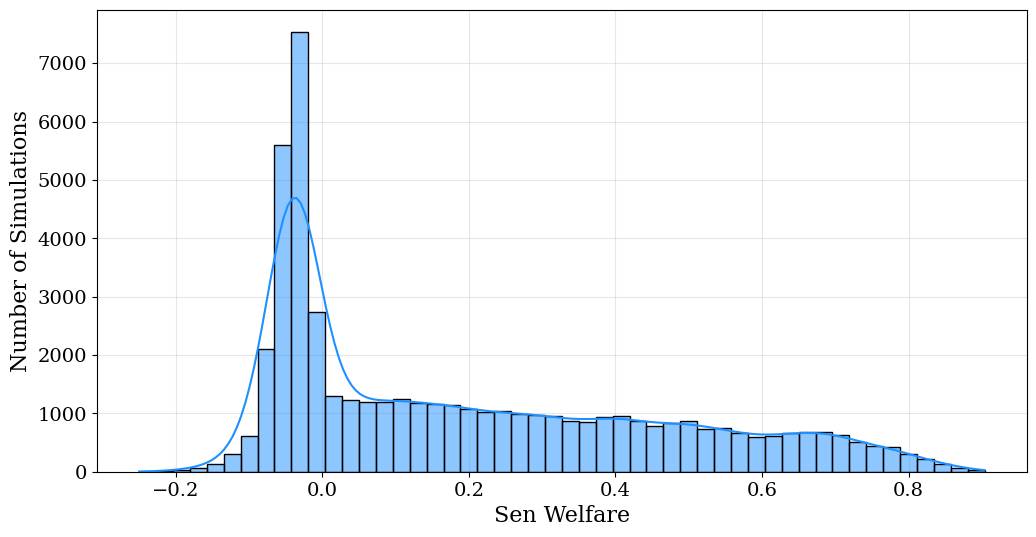

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(sim_df['sen_welfare'], bins=50, kde=True, color='dodgerblue')
plt.xlabel("Sen Welfare")
plt.ylabel("Number of Simulations")
plt.grid()
plt.show()

### Heatmaps for veracity differential and sen welfare over parameter space

In [ ]:
# bin resolution
N_BINS = 10

param_cols = [
    "v_cost",
    "loss",
    "tpr",
    "fpr",
    "p_fake"
]

param_pairs = list(itertools.combinations(param_cols, 2))
len(param_pairs)

10

In [ ]:
def plot_hexbin_grid(df, value_col, title, bins=N_BINS):
    fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
    axes = axes.flatten()

    for ax, (xparam, yparam) in zip(axes, param_pairs):
        hb = ax.hexbin(
            df[xparam],
            df[yparam],
            C=df[value_col],
            reduce_C_function=np.mean,
            gridsize=bins,
            cmap="viridis"
        )
        ax.set_xlabel(xparam)
        ax.set_ylabel(yparam)
        ax.set_title(f"{xparam} vs {yparam}")

    fig.suptitle(title, fontsize=18)
    fig.tight_layout()
    cbar = fig.colorbar(hb, ax=axes.tolist())
    cbar.set_label(value_col)
    plt.show()

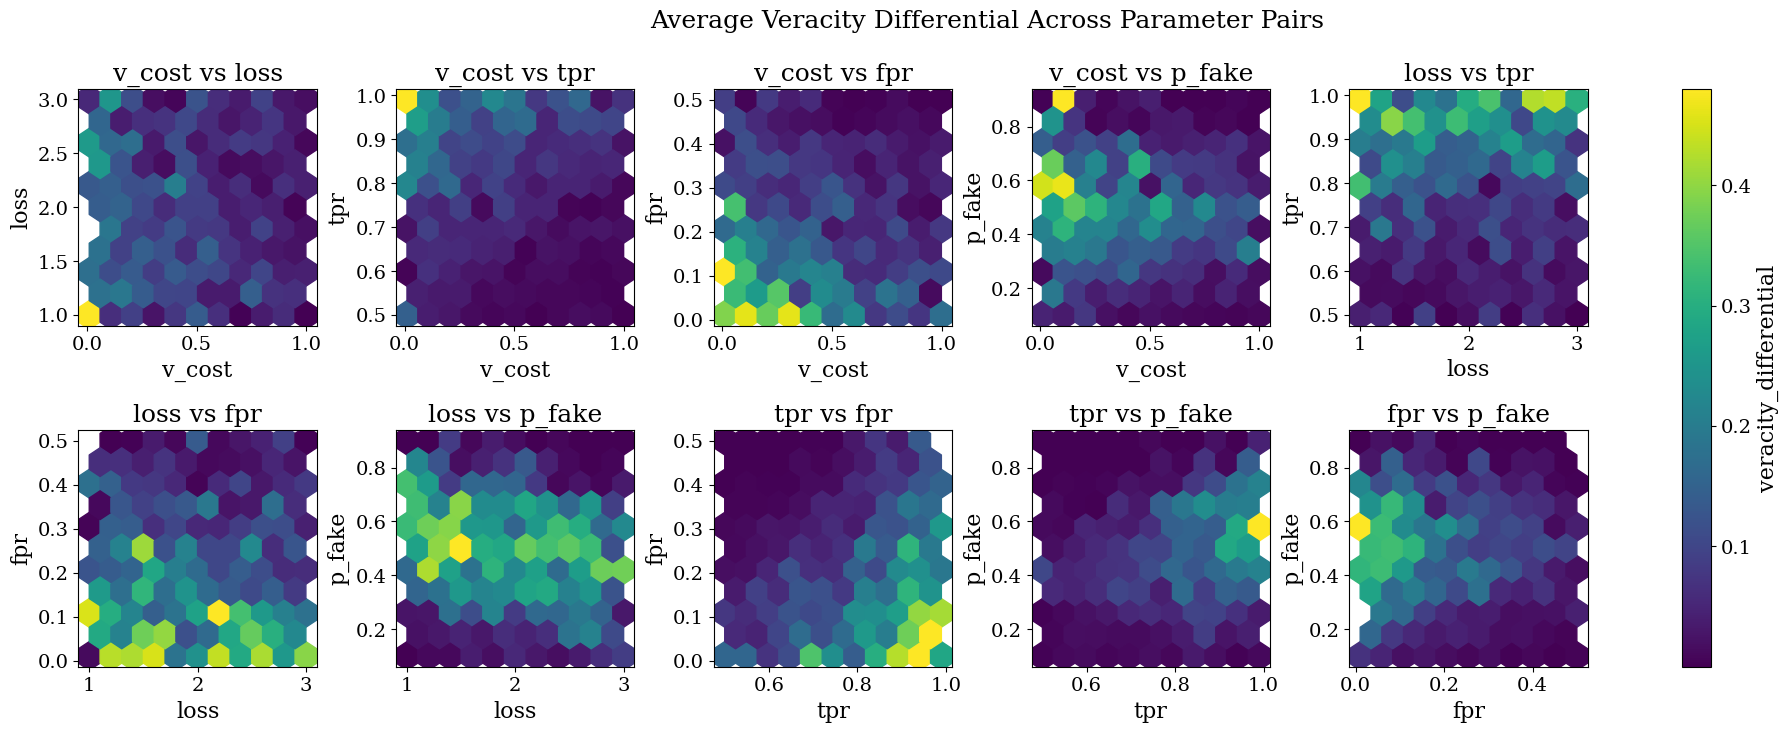

In [ ]:
plot_hexbin_grid(
    sim_df,
    value_col="veracity_differential",
    title="Average Veracity Differential Across Parameter Pairs"
)

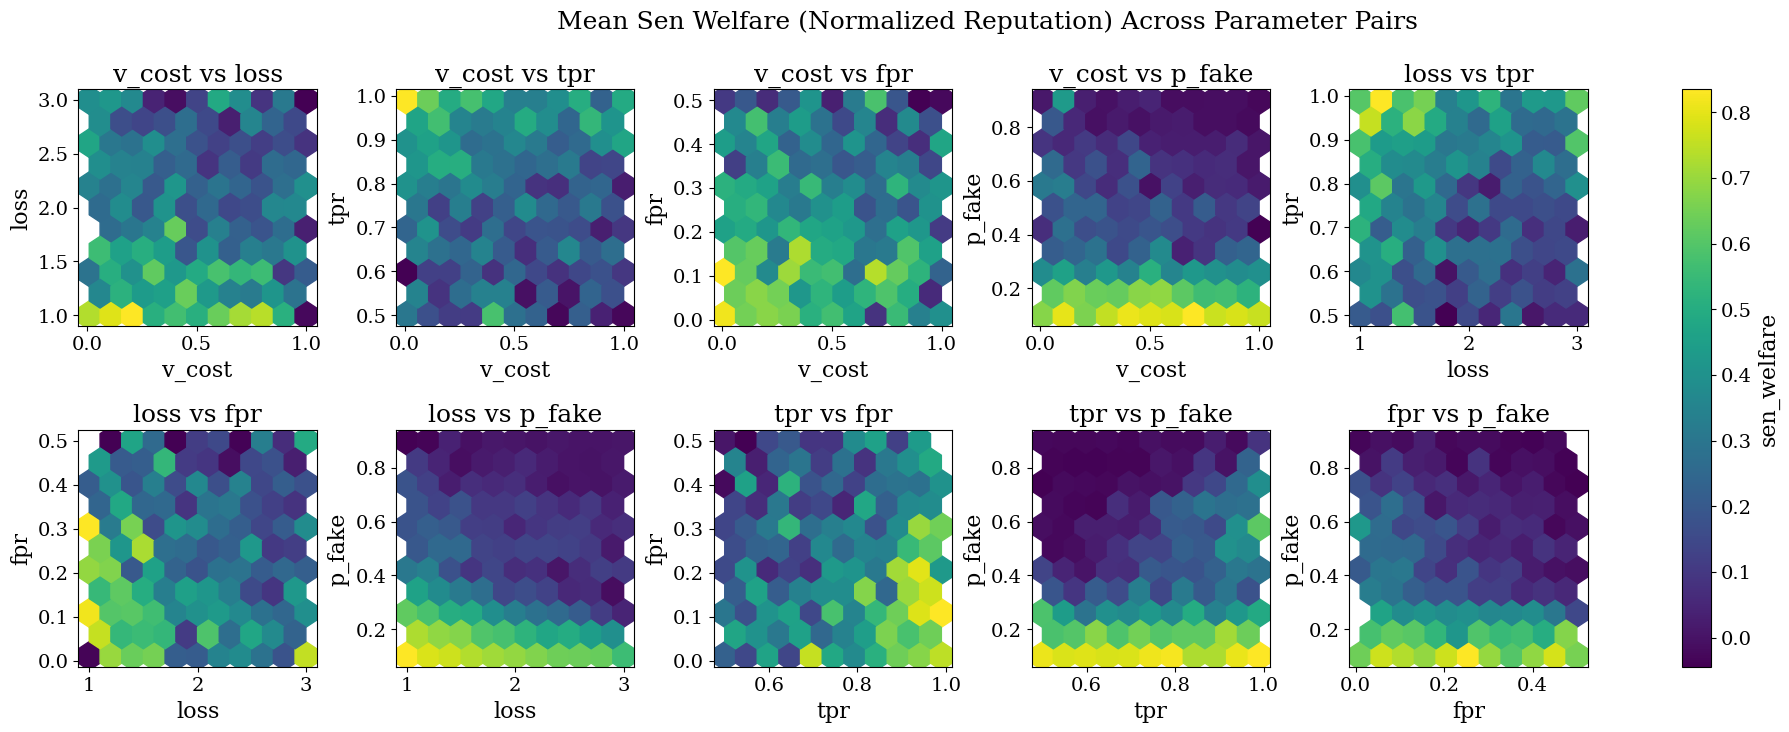

In [ ]:
plot_hexbin_grid(
    sim_df,
    value_col="sen_welfare",
    title="Mean Sen Welfare (Normalized Reputation) Across Parameter Pairs"
)

### Average Veracity Differential Versus Average Normalized Reputation

In [ ]:
l1 = list(sim_df["global_sim_id"])
l2 = list(sim_df["lhs_id"])
D = {l1[i]:l2[i] for i in range(len(l1))}
node_df["lhs_id"] = [D[x] for x in list(node_df["global_sim_id"])]

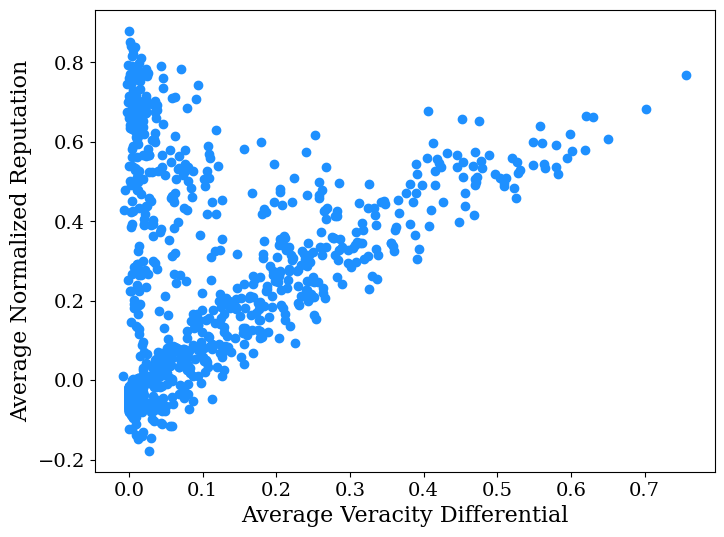

In [190]:
plt.scatter(
    sim_df.groupby("lhs_id").mean()["veracity_differential"],
    node_df.groupby("lhs_id").mean()["normalized_rep"],
    color="dodgerblue"
)

plt.xlabel("Average Veracity Differential")
plt.ylabel("Average Normalized Reputation")
plt.show()

### Average Average Verification Rate Versus Veracity Differential

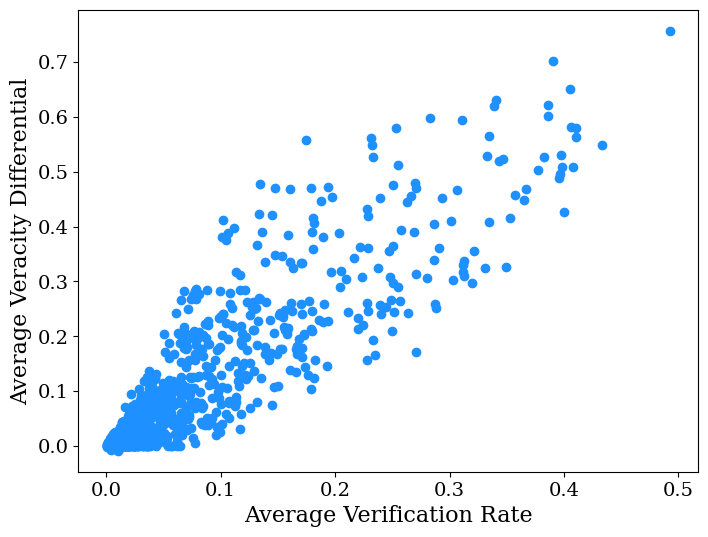

In [199]:
plt.scatter(
    sim_df.groupby("lhs_id").mean()["avg_verify_rate"],
    sim_df.groupby("lhs_id").mean()["veracity_differential"],
    color="dodgerblue"
)

plt.ylabel("Average Veracity Differential")
plt.xlabel("Average Verification Rate")
plt.show()

### Average Veracity Differential Versus Average Reputation

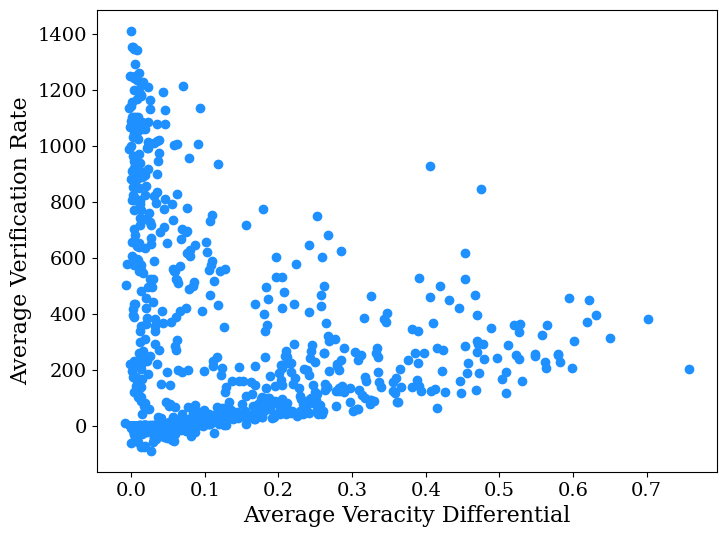

In [196]:
plt.scatter(
    sim_df.groupby("lhs_id").mean()["veracity_differential"],
    sim_df.groupby("lhs_id").mean()["avg_welfare"],
    color="dodgerblue"
)

plt.xlabel("Average Veracity Differential")
plt.ylabel("Average Verification Rate")
plt.show()

### True and Fake Cascade Sizes

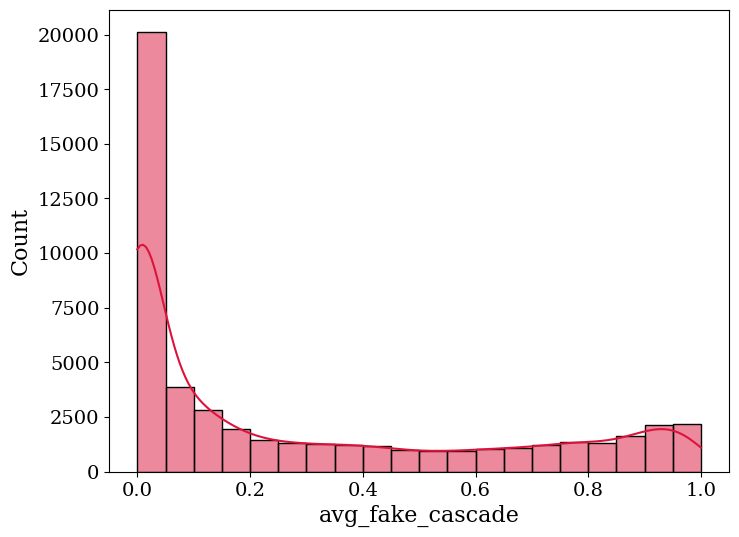

In [154]:
sns.histplot(sim_df["avg_fake_cascade"], bins=20, kde=True, color="crimson")
plt.show()

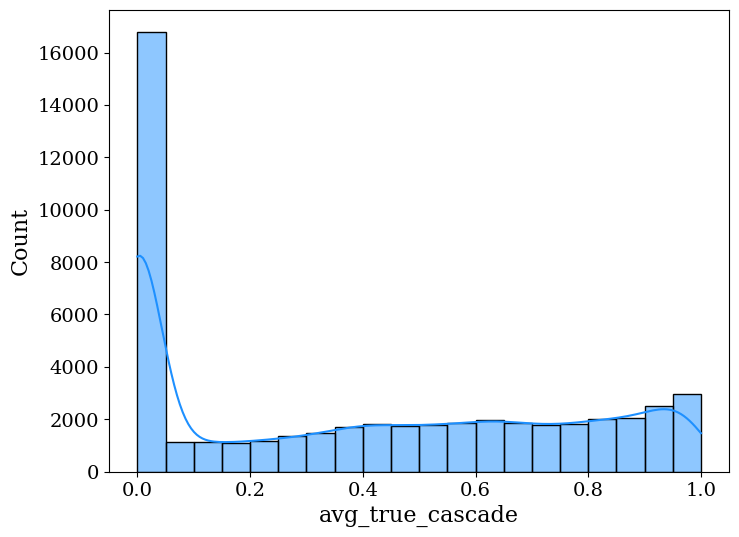

In [155]:
sns.histplot(sim_df["avg_true_cascade"], bins=20, kde=True, color="dodgerblue")
plt.show()

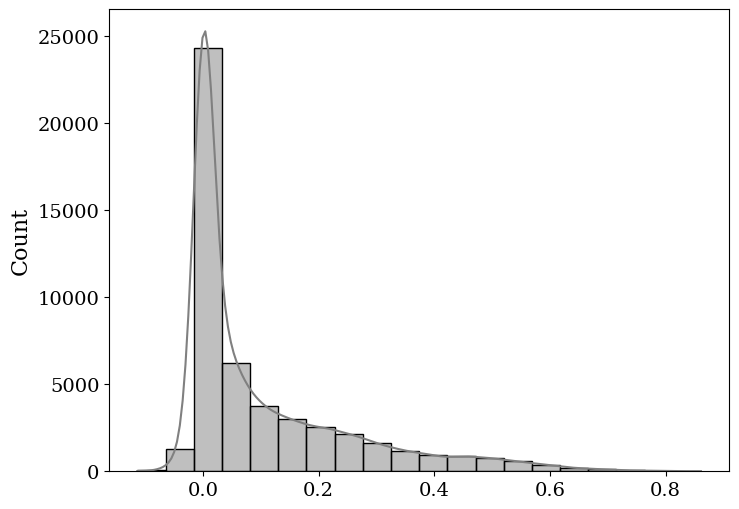

In [157]:
sns.histplot(sim_df["avg_true_cascade"] - sim_df["avg_fake_cascade"], bins=20, kde=True, color="grey")
plt.show()

### Agent belief of global truth prevalence vs. actual

In [ ]:
# Calculate true prevalence for all rows
node_df = node_df.copy()
node_df['true_prevalence'] = node_df['true_alpha'] / (node_df['true_alpha'] + node_df['true_beta'])

# Merge node_df with sim_df to get p_true in one shot
merged = node_df.merge(
    sim_df[['global_sim_id', 'p_fake']],
    on='global_sim_id',
    how='left'
)

# Compute p_true
merged['p_true'] = 1 - merged['p_fake']

# Group by p_true and sum true_prevalence
data = merged.groupby('p_true')['true_prevalence'].mean().to_dict()

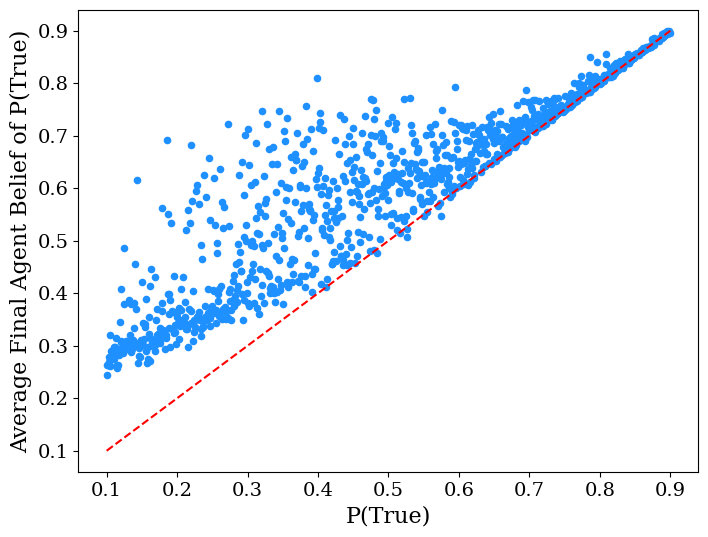

In [144]:
plt.scatter(
    list(data.keys()),
    list(data.values()),
    color="dodgerblue",
    s=20
)
plt.xlabel("P(True)")
plt.ylabel("Average Final Agent Belief of P(True)")

plt.plot(
    np.linspace(0.1, 0.9, 2),
    np.linspace(0.1, 0.9, 2),
    color="red",
    linestyle="dashed"
)

plt.show()